# `bbox_size_capped_v1` final test results

Plots the confusion matrix for the 2D and 2.5D final models
They were evaluated once on the held-out test set (`split_test.csv`).

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report

LABELS = ["low_vascular_contact", "high_vascular_contact"]

RESULTS_DIR = Path("final_model/bbox_size_capped_v1")
CROP_VERSION = "bbox_size_capped_v1"

results = {}
for mode, label in [("2d", "2D"), ("2.5d", "2.5D")]:
    json_path = RESULTS_DIR / mode / f"test_results_{CROP_VERSION}_{mode}.json"
    with open(json_path) as f:
        results[label] = json.load(f)

## [[TN, FP], [FN, TP]]
cm_2d = np.array(results["2D"]["confusion_matrix"])
cm_2_5d = np.array(results["2.5D"]["confusion_matrix"])

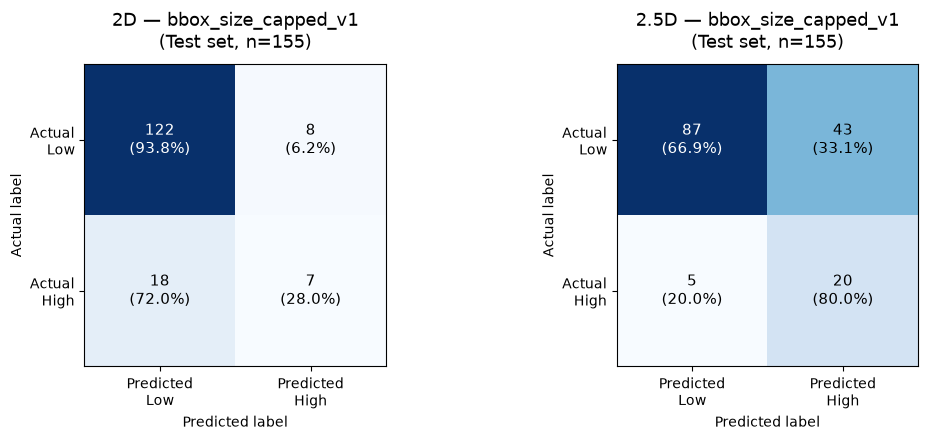

In [ ]:
def plot_confusion_matrix(cm, title, ax):
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Predicted\nLow", "Predicted\nHigh"])
    ax.set_yticklabels(["Actual\nLow", "Actual\nHigh"])
    ax.set_title(title, fontsize=13, pad=12)

    row_totals = cm.sum(axis=1, keepdims=True)
    cm_pct = cm / row_totals * 100

    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > thresh else "black"
            ax.text(j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=11)

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    return im


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

plot_confusion_matrix(cm_2d, "2D — bbox_size_capped_v1\n(Test set, n=155)", axes[0])
plot_confusion_matrix(cm_2_5d, "2.5D — bbox_size_capped_v1\n(Test set, n=155)", axes[1])

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## Summary metrics table

In [ ]:
summary_df = pd.DataFrame(results).T
summary_df = summary_df[["auroc", "auprc", "recall", "precision", "f1", "specificity", "accuracy"]]
summary_df.columns = ["AUROC", "AUPRC", "Recall", "Precision", "F1", "Specificity", "Accuracy"]
summary_df = summary_df.round(4)
summary_df

,AUROC,AUPRC,Recall,Precision,F1,Specificity,Accuracy
2D,0.736308,0.442974,0.28,0.466667,0.35,0.938462,0.832258
2.5D,0.802154,0.539041,0.8,0.31746,0.454545,0.669231,0.690323


In [7]:
summary_df.to_csv("test_results_summary.csv")
print("Saved to test_results_summary.csv")

Saved to test_results_summary.csv


## Cross-validation compared to test AUROC comparison

In [ ]:
cv_vs_test = pd.DataFrame({
    "CV AUROC (mean)": [0.7163516468363407, 0.7295076235127256],
    "CV AUROC (std)":  [0.023009147657880893, 0.059545117476769764],
    "Test AUROC":      [results["2D"]["auroc"], results["2.5D"]["auroc"]],
}, index=["2D", "2.5D"]).round(4)
cv_vs_test

,CV AUROC (mean),CV AUROC (std),Test AUROC
2D,0.7164,0.0230,0.7363
2.5D,0.7295,0.0595,0.8022


In [3]:
def reconstruct_labels_from_cm(cm):
    tn, fp, fn, tp = cm.ravel()
    y_true = [0] * tn + [0] * fp + [1] * fn + [1] * tp
    y_pred = [0] * tn + [1] * fp + [0] * fn + [1] * tp
    return y_true, y_pred


for name, cm in [("2D", cm_2d), ("2.5D", cm_2_5d)]:
    y_true, y_pred = reconstruct_labels_from_cm(cm)
    print(f"{name}")
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))

2D
                       precision    recall  f1-score   support

 low_vascular_contact     0.8714    0.9385    0.9037       130
high_vascular_contact     0.4667    0.2800    0.3500        25

             accuracy                         0.8323       155
            macro avg     0.6690    0.6092    0.6269       155
         weighted avg     0.8061    0.8323    0.8144       155

2.5D
                       precision    recall  f1-score   support

 low_vascular_contact     0.9457    0.6692    0.7838       130
high_vascular_contact     0.3175    0.8000    0.4545        25

             accuracy                         0.6903       155
            macro avg     0.6316    0.7346    0.6192       155
         weighted avg     0.8443    0.6903    0.7307       155

